In [49]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.ticker import ScalarFormatter
import pandas as pd
from planet_cookbook import read_reports as rr
import os
import rebound
import seaborn as sns

sol_to_earth = 332946.078
G = 6.6743* 10**(-11) #N⋅m2/kg2
M_sun = 1.989e+33 #g
AU = 1.496e+13 #cm

params = {
   'axes.labelsize': 15,
   'font.size': 15,
   'legend.fontsize': 10,
   'xtick.labelsize': 15,
   'ytick.labelsize': 15,
   'text.usetex': True, #to use TeX in your labels
   'font.family':'serif',
   'axes.titlesize': 15
   }
rcParams.update(params)

#Color-blind friendly pallete
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#8B8D8B",  # Medium Grey
    "#5D3A9B",   # Muted Purple'
]

In [73]:
base_cols = ['t', 'type', 'b', 
              'hash_t', 'm_t', 'r_t', 'x_t', 'y_t', 'z_t',
              'hash_p', 'm_p', 'r_p', 'x_p', 'y_p', 'z_p']

rows = []
for sim_id in range(131,141):
    dir_path = f"/Users/honeyeah/Codes/data/cham_bi_tajer/cham_bi_tajer_{sim_id}/collision_report.txt"
    with open(dir_path, "r") as f:
        for line in f:
            parts = line.strip().split()

            # First 15 entries = fixed values
            base_values = parts[:len(base_cols)]

            # Remaining entries are fragments in pairs: (hash_frag, m_frag)
            frag_values = parts[len(base_cols):]
            frag_pairs = list(zip(frag_values[::2], frag_values[1::2]))  # [(hash1, m1), (hash2, m2), ...]

            # If you want one row per collision (with all fragments concatenated):
            row_dict = dict(zip(base_cols, base_values))
            for i, (h, m) in enumerate(frag_pairs):
                row_dict[f"hash_frag_{i+1}"] = h
                row_dict[f"m_frag_{i+1}"] = m

            row_dict["sim_id"] = sim_id
            rows.append(row_dict)

# Create DataFrame
cham_bi_df = pd.DataFrame(rows)

# Convert numeric columns from string to float/int where possible
for col in cham_bi_df.columns:
    cham_bi_df[col] = pd.to_numeric(cham_bi_df[col], errors='ignore')


/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_31670/2009675982.py:33: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  cham_bi_df[col] = pd.to_numeric(cham_bi_df[col], errors='ignore')


In [74]:
cham_bi_df.columns

Index(['t', 'type', 'b', 'hash_t', 'm_t', 'r_t', 'x_t', 'y_t', 'z_t', 'hash_p',
       'm_p', 'r_p', 'x_p', 'y_p', 'z_p', 'sim_id', 'hash_frag_1', 'm_frag_1',
       'hash_frag_2', 'm_frag_2', 'hash_frag_3', 'm_frag_3', 'hash_frag_4',
       'm_frag_4', 'hash_frag_5', 'm_frag_5', 'hash_frag_6', 'm_frag_6',
       'hash_frag_7', 'm_frag_7', 'hash_frag_8', 'm_frag_8', 'hash_frag_9',
       'm_frag_9', 'hash_frag_10', 'm_frag_10', 'hash_frag_11', 'm_frag_11',
       'hash_frag_12', 'm_frag_12', 'hash_frag_13', 'm_frag_13',
       'hash_frag_14', 'm_frag_14', 'hash_frag_15', 'm_frag_15',
       'hash_frag_16', 'm_frag_16', 'hash_frag_17', 'm_frag_17',
       'hash_frag_18', 'm_frag_18', 'hash_frag_19', 'm_frag_19',
       'hash_frag_20', 'm_frag_20', 'hash_frag_21', 'm_frag_21',
       'hash_frag_22', 'm_frag_22', 'hash_frag_23', 'm_frag_23',
       'hash_frag_24', 'm_frag_24'],
      dtype='object')

In [75]:
rows = []
base_cols = ['t', 'type', 'b', 
              'hash_t', 'm_t', 'r_t', 'x_t', 'y_t', 'z_t',
              'hash_p', 'm_p', 'r_p', 'x_p', 'y_p', 'z_p']

for sim_id in range(61,71):
    dir_path = f"/Users/honeyeah/Codes/data/ueda_v5/ueda_v5_{sim_id}/collision_report.txt"
    with open(dir_path, "r") as f:
        for line in f:
            parts = line.strip().split('\t')

            # First 15 entries = fixed values
            base_values = parts[:len(base_cols)]

            # Remaining entries are fragments in pairs: (hash_frag, m_frag)
            frag_values = parts[len(base_cols):]
            frag_pairs = list(zip(frag_values[::2], frag_values[1::2]))  # [(hash1, m1), (hash2, m2), ...]

            # If you want one row per collision (with all fragments concatenated):
            row_dict = dict(zip(base_cols, base_values))
            for i, (h, m) in enumerate(frag_pairs):
                row_dict[f"hash_frag_{i+1}"] = h
                row_dict[f"m_frag_{i+1}"] = m

            row_dict["sim_id"] = sim_id
            rows.append(row_dict)

# Create DataFrame
ueda_df = pd.DataFrame(rows)

# Convert numeric columns from string to float/int where possible
for col in ueda_df.columns:
    ueda_df[col] = pd.to_numeric(ueda_df[col], errors='ignore')

/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_31670/1305774270.py:33: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  ueda_df[col] = pd.to_numeric(ueda_df[col], errors='ignore')


In [76]:
cham_bi_df['d_t'] = np.sqrt(cham_bi_df['x_t']**2 + cham_bi_df['y_t']**2)
cham_bi_df['d_p'] = np.sqrt(cham_bi_df['x_p']**2 + cham_bi_df['y_p']**2)
cham_bi_df = cham_bi_df[cham_bi_df['d_t'] < 3]


ueda_df['d_t'] = np.sqrt(ueda_df['x_t']**2 + ueda_df['y_t']**2)
ueda_df['d_p'] = np.sqrt(ueda_df['x_p']**2 + ueda_df['y_p']**2)
ueda_df = ueda_df[ueda_df['d_t'] < 3]

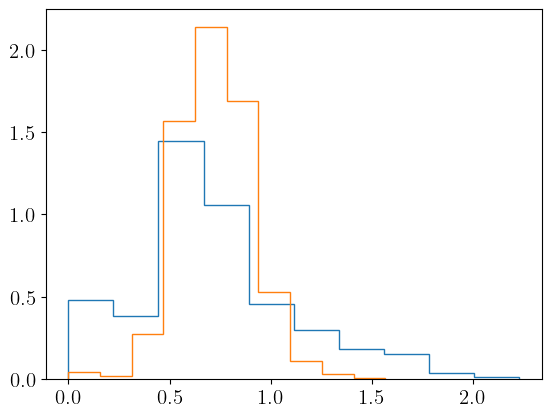

In [77]:
plt.hist(cham_bi_df['d_t'], density='True', bins=10, histtype='step')
plt.hist(ueda_df['d_t'], density='True', bins=10, histtype='step')

plt.show()

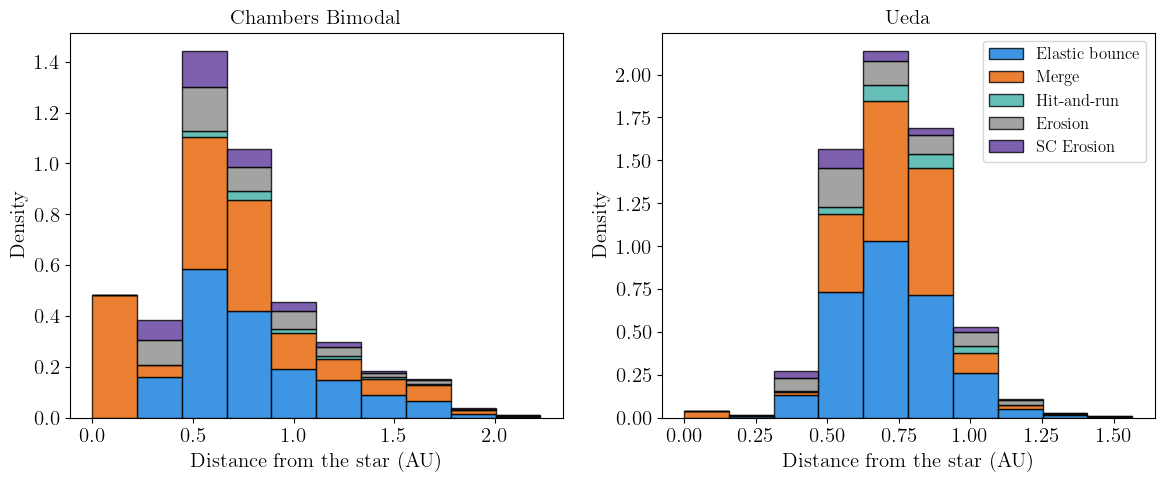

In [55]:
plt.figure(figsize=(14,5))

collision_types = [0, 1, 2, 3, 4]   # your 4 collision types
type_names = ['Elastic bounce', 'Merge', 'Hit-and-run', 'Erosion', 'SC Erosion']

# Extract arrays of d_t for each type
datasets = [cham_bi_df[cham_bi_df['type'] == t]['d_t'] for t in collision_types]
plt.subplot(1,2,1)
plt.hist(
    datasets,
    bins=10,
    density=True,       # normalize to show proportions
    histtype='barstacked',
    color=colors,
    label=[f'Type {t}' for t in collision_types],
    edgecolor='black',
    alpha=0.8
)

plt.xlabel('Distance from the star (AU)')
plt.ylabel('Density')
plt.title('Chambers Bimodal')

datasets = [ueda_df[ueda_df['type'] == t]['d_t'] for t in collision_types]
plt.subplot(1,2,2)
plt.hist(
    datasets,
    bins=10,
    density=True,       # normalize to show proportions
    histtype='barstacked',
    color=colors,
    label=[f'{type_names[t]}' for t in collision_types],
    edgecolor='black',
    alpha=0.8
)

plt.xlabel('Distance from the star (AU)')
plt.ylabel('Density')
plt.title('Ueda')
plt.legend(fontsize=12)


plt.show()

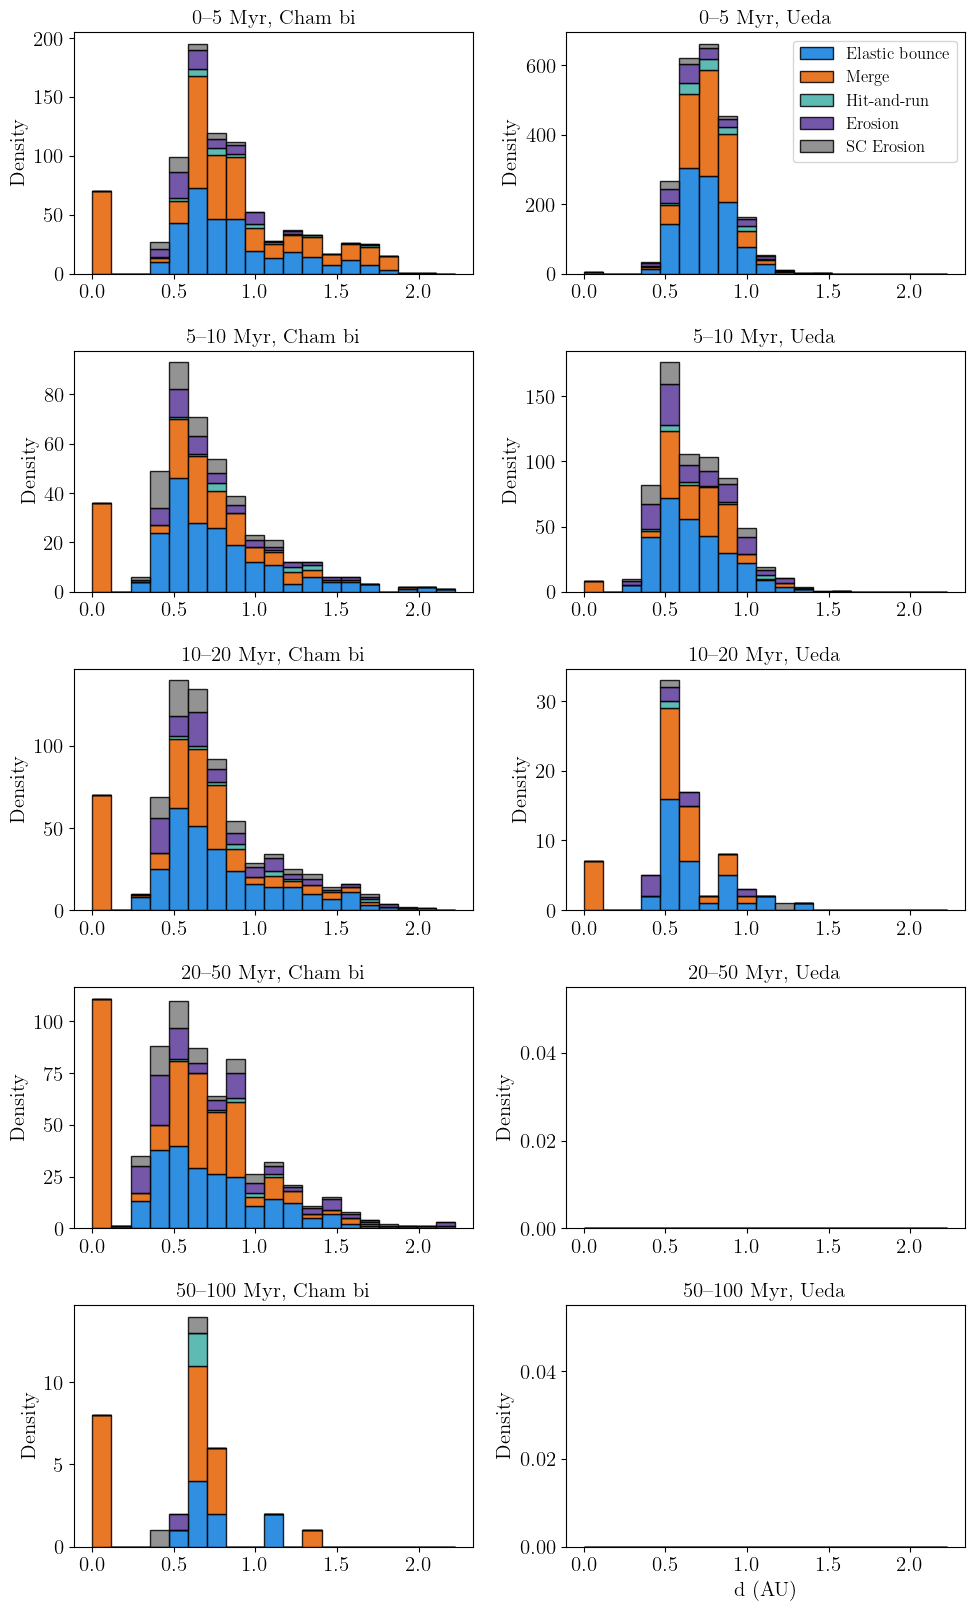

<Figure size 640x480 with 0 Axes>

In [56]:
# Define your epochs (in Myr)
colors = [
    "#0C7BDC",  # Vibrant Blue
    "#E66100",  # Bright Orange
    "#40B0A6",  # Teal/Aqua
    "#5D3A9B",   # Muted Purple'
    'gray'
]

epochs = [
    (0, 5e6),
    (5e6, 10e6),
    (10e6, 20e6),
    (20e6, 50e6),
    (50e6, 100e6),
]

plt.figure(figsize=(10,20))

bins = np.linspace(cham_bi_df['d_t'].min(), cham_bi_df['d_t'].max(), 20)

for i, (tmin, tmax) in enumerate(epochs):
    plt.subplot(6,2,2 * i + 1)
    subset = cham_bi_df[(cham_bi_df['t'] >= tmin) & (cham_bi_df['t'] < tmax)]

    # Group d_t by collision type
    datasets = [subset[subset['type'] == t]['d_t'] for t in collision_types]

    # Plot stacked histogram for this epoch
    plt.hist(
        datasets,
        bins=bins,
        #density=True,
        histtype='barstacked',
        color=colors,
        edgecolor='black',
        label=[f'Type {t}' for t in collision_types],
        alpha=0.85
    )
    plt.ylim(0,)
    plt.ylabel('Density')
    plt.title(f'{tmin/1e6:.0f}–{tmax/1e6:.0f} Myr, Cham bi')

for i, (tmin, tmax) in enumerate(epochs):
    plt.subplot(6,2,2 * i + 2)
    subset = ueda_df[(ueda_df['t'] >= tmin) & (ueda_df['t'] < tmax)]

    # Group d_t by collision type
    datasets = [subset[subset['type'] == t]['d_t'] for t in collision_types]

    # Plot stacked histogram for this epoch
    plt.hist(
        datasets,
        bins=bins,
        #density=True,
        histtype='barstacked',
        color=colors,
        edgecolor='black',
        label=[type_names[i] for i in range(len(collision_types))],
        alpha=0.85
    )
    if i == 0:
        plt.legend(fontsize=12)
    plt.ylim(0,)
    plt.ylabel('Density')
    plt.title(f'{tmin/1e6:.0f}–{tmax/1e6:.0f} Myr, Ueda')

# Only label x-axis once at the bottom
plt.xlabel('d (AU)')

# Put one legend for all at the bottom
#handles, labels = axes[0].get_legend_handles_labels()
#fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, fontsize=10)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

plt.savefig('stats.pdf', dpi=200)


In [57]:
with_the_sun_cham_bi = cham_bi_df[cham_bi_df['hash_t'] == 0]
with_the_sun_ueda = ueda_df[ueda_df['hash_t'] == 0]

In [58]:
len(with_the_sun_cham_bi)

295

In [59]:
with_the_sun_cham_bi

,t,type,b,hash_t,m_t,r_t,x_t,y_t,z_t,hash_p,...,hash_frag_21,m_frag_21,hash_frag_22,m_frag_22,hash_frag_23,m_frag_23,hash_frag_24,m_frag_24,d_t,d_p
53,953525.4,1,0.099575,0,1.000000,0.1,1.948967e-09,1.996227e-09,-4.362400e-11,-4.362400e-11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.789874e-09,0.099638
58,1224375.0,1,0.097930,0,1.000000,0.1,2.742791e-09,-3.597126e-10,-1.138792e-10,-1.138792e-10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.766278e-09,0.098796
78,2305767.0,1,0.099951,0,1.000000,0.1,-1.774376e-10,2.787672e-09,1.785042e-10,1.785042e-10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.793313e-09,0.099761
79,2344411.0,1,0.099952,0,1.000000,0.1,-2.444287e-09,1.363486e-09,1.036266e-11,1.036266e-11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.798863e-09,0.099959
80,2505927.0,1,0.099770,0,1.000000,0.1,1.988029e-09,-1.964770e-09,-9.841265e-11,-9.841265e-11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.795099e-09,0.099825
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3070,27264480.0,1,0.098880,0,1.000001,0.1,-1.307229e-10,-2.786180e-09,-1.164918e-10,-1.164918e-10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.789245e-09,0.099616
3071,27318280.0,1,0.099737,0,1.000001,0.1,1.205260e-09,7.038082e-10,-4.626014e-11,-4.626014e-11,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.395707e-09,0.099693
3072,27425500.0,1,0.100005,0,1.000001,0.1,8.004619e-10,1.138009e-09,-1.562877e-10,-1.562877e-10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.391332e-09,0.099381
3076,27885030.0,1,0.099987,0,1.000001,0.1,-1.292062e-09,5.288288e-10,-1.021047e-10,-1.021047e-10,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.396096e-09,0.099721


(array([  4.,   4.,  13.,  47., 109.,  69.,  37.,   8.,   3.,   1.]),
 array([-1.052692e-09, -8.321386e-10, -6.115852e-10, -3.910318e-10,
        -1.704784e-10,  5.007500e-11,  2.706284e-10,  4.911818e-10,
         7.117352e-10,  9.322886e-10,  1.152842e-09]),
 <BarContainer object of 10 artists>)

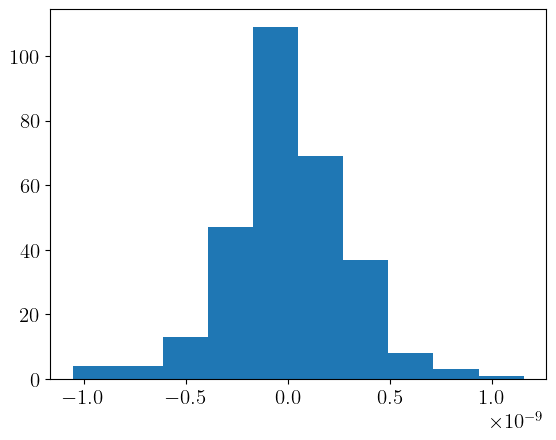

In [60]:
plt.hist(with_the_sun['hash_p'])

In [61]:
len(with_the_sun_ueda)

19

# Cham_cont

In [62]:
base_cols = ['t', 'type', 'b', 
              'hash_t', 'm_t', 'r_t',
              'hash_p', 'r_p']

rows = []
for sim_id in range(1,60):
    dir_path = f"/Users/honeyeah/Codes/data/cham_cont/cham_cont_{sim_id}/collision_report.txt"
    with open(dir_path, "r") as f:
        for line in f:
            parts = line.strip().split('\t')

            # First 15 entries = fixed values
            base_values = parts[:len(base_cols)]

            # Remaining entries are fragments in pairs: (hash_frag, m_frag)
            frag_values = parts[len(base_cols):]
            frag_pairs = list(zip(frag_values[::2], frag_values[1::2]))  # [(hash1, m1), (hash2, m2), ...]

            # If you want one row per collision (with all fragments concatenated):
            row_dict = dict(zip(base_cols, base_values))
            for i, (h, m) in enumerate(frag_pairs):
                row_dict[f"hash_frag_{i+1}"] = h
                row_dict[f"m_frag_{i+1}"] = m

            row_dict["sim_id"] = sim_id
            rows.append(row_dict)

# Create DataFrame
cham_cont_df = pd.DataFrame(rows)

# Convert numeric columns from string to float/int where possible
for col in cham_cont_df.columns:
    cham_cont_df[col] = pd.to_numeric(cham_cont_df[col], errors='ignore')

/var/folders/g0/fl404sj151l2v9xcdkjz9fq80000gn/T/ipykernel_31670/1584798757.py:33: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  cham_cont_df[col] = pd.to_numeric(cham_cont_df[col], errors='ignore')


In [63]:
cham_cont_df

,t,type,b,hash_t,m_t,r_t,hash_p,r_p,sim_id,hash_frag_1,...,hash_frag_44,m_frag_44,hash_frag_45,m_frag_45,hash_frag_46,m_frag_46,hash_frag_47,m_frag_47,hash_frag_48,m_frag_48
0,5.897494e+03,1,0.000032,5,2.808060e-07,0.000024,6,0.000011,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,9.312130e+03,1,0.000027,17,7.249733e-07,0.000032,15,0.000014,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9.650009e+03,1,0.000016,28,5.169796e-07,0.000029,31,0.000013,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.244862e+04,0,0.000018,64,2.647569e-08,0.000011,73,0.000010,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.649902e+04,1,0.000017,39,4.079619e-07,0.000027,48,0.000012,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26140,5.523204e+07,1,0.000025,17,2.435850e-06,0.000049,3149440925,0.000009,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26141,5.526279e+07,0,0.000032,5,6.801464e-07,0.000032,1149406307,0.000009,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26142,5.642195e+07,1,0.000025,5,6.979020e-07,0.000032,1149406307,0.000009,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26143,5.643353e+07,1,0.000047,17,2.478788e-06,0.000049,32,0.000013,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [64]:
cham_cont_with_the_sun

,t,type,b,hash_t,m_t,r_t,hash_p,r_p,sim_id,hash_frag_1,...,hash_frag_44,m_frag_44,hash_frag_45,m_frag_45,hash_frag_46,m_frag_46,hash_frag_47,m_frag_47,hash_frag_48,m_frag_48
28,844008.5,1,0.099373,0,1.000000,0.1,120,0.000009,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,866443.5,1,0.098663,0,1.000000,0.1,146,0.000009,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
35,1177121.0,1,0.099166,0,1.000000,0.1,141,0.000009,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
37,1299405.0,1,0.099382,0,1.000000,0.1,111,0.000009,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,2300549.0,1,0.099366,0,1.000000,0.1,126,0.000009,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
26124,46413280.0,1,0.099023,0,1.000002,0.1,690117576,0.000009,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26125,46462610.0,1,0.098906,0,1.000002,0.1,44,0.000012,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26128,46845190.0,1,0.098987,0,1.000002,0.1,937177227,0.000009,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
26130,49496350.0,1,0.099980,0,1.000002,0.1,2211003714,0.000009,59,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [65]:
cham_cont_with_the_sun = cham_cont_df[cham_cont_df['hash_t'] == 0]
len(cham_cont_with_the_sun)/len(cham_cont_df['sim_id'].unique())

91.33898305084746

In [66]:
len(with_the_sun_cham_bi)/len(cham_bi_df['sim_id'].unique())

29.5

In [67]:
frags_to_sun = cham_cont_with_the_sun[cham_cont_with_the_sun['hash_p'] > 154]

In [68]:
len(frags_to_sun)/len(cham_cont_with_the_sun)

0.3191686769344962

In [69]:
60 * 154

9240

In [70]:
closer_pls = cham_cont_df[cham_cont_df['hash_t'] < 15]
outer_pls = cham_cont_df[cham_cont_df['hash_t'] >= 15]

(array([1642.,    0., 6800.,    0.,    0.,  153.,    0.,  658.,    0.,
         140.]),
 array([0. , 0.4, 0.8, 1.2, 1.6, 2. , 2.4, 2.8, 3.2, 3.6, 4. ]),
 <BarContainer object of 10 artists>)

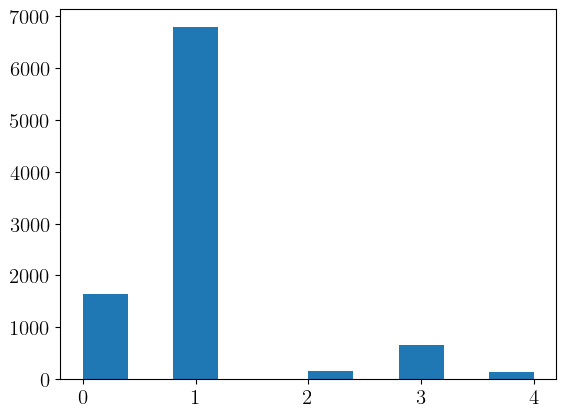

In [71]:
plt.hist(closer_pls['type'])